# 01 · Understanding the CrimeBase data

**Question this notebook answers:** what is in the Kaggle download, how trustworthy is it, and
what can honestly be *classified* with it?

The download is one zip of NCRB (India's National Crime Records Bureau) statistics in long format,
not a table of individual crimes. Everything below is computed from the zip in place; nothing is
extracted or modified. Design context is in [`docs/design.md`](../docs/design.md).

In [1]:
import numpy as np
import pandas as pd

from crimebase import viz
from crimebase.config import load_config

cfg = load_config()
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_colwidth = 80
pd.options.display.width = 140

import zipfile
from crimebase.clean import build_panel, head_key
from crimebase.data import load_india_year, load_news, load_state_year

## 1. What is in the zip

In [2]:
with zipfile.ZipFile(cfg.paths.raw_zip) as zf:
    inventory = pd.DataFrame(
        [(i.filename, i.file_size / 1e6, i.compress_size / 1e6) for i in zf.infolist()],
        columns=["file", "MB", "MB zipped"],
    ).sort_values("MB", ascending=False, ignore_index=True)
inventory.round(2)

,file,MB,MB zipped
0,crime_state_year.csv,113.060,9.520
1,facts_raw.parquet,27.250,20.290
2,facts.parquet,25.020,18.380
3,facts_pdf_lowconf.parquet,3.280,2.540
4,crime_india_year.csv,3.000,0.310
5,documents.csv,2.710,0.430
6,news.parquet,0.440,0.380
7,parse_state.json,0.150,0.070
8,news_events.parquet,0.120,0.100
9,unmapped_states.csv,0.070,0.020


Three groups of files:

* **Clean tables** `crime_state_year.csv` and `crime_india_year.csv`: one number per state/UT (or
  all-India) × year × *scope* × crime head × metric. These are the modelling tables.
* **`facts*.parquet`, `documents.csv`, `parse_state.json`**: the raw parsed cells and the catalogue of
  source documents. They are provenance, not model input.
* **`news.parquet`**: a sample of crime news articles. The only record-level data in the zip.

In [3]:
state_year = load_state_year(cfg)
india_year = load_india_year(cfg)
news = load_news(cfg)
pd.Series({"state_year rows": len(state_year), "india_year rows": len(india_year), "news rows": len(news)})

state_year rows    668240
india_year rows     21942
news rows            1487
dtype: int64

## 2. The state-year table

In [4]:
pd.DataFrame(
    {"dtype": state_year.dtypes.astype(str), "nulls": state_year.isna().sum(), "distinct": state_year.nunique()}
)

,dtype,nulls,distinct
state_code,str,0,36
state,str,0,36
year,int64,0,22
scope,str,0,9
crime_head,str,0,2490
crime_category,str,0,24
metric,str,0,7
value,float64,0,18004
disputed,bool,0,2
source,str,0,2


In [5]:
state_year.head(6)

,state_code,state,year,scope,crime_head,crime_category,metric,value,disputed,source,table_id,file
0,AN,Andaman and Nicobar Islands,2001,children,Abetment of Suicide,suicide,cases_registered,0.000,False,state_table,NaN,2434ebc0dccdab92.xls
1,AN,Andaman and Nicobar Islands,2001,children,Abetment of Suicide of Child,suicide,persons_arrested,0.000,False,state_table,NaN,d1fbb0b66c86215b.xlsx
2,AN,Andaman and Nicobar Islands,2001,children,Assault on Women with Intent to Outrage her Modesty,sexual_offence,persons_arrested,0.000,False,state_table,NaN,d1fbb0b66c86215b.xlsx
3,AN,Andaman and Nicobar Islands,2001,children,Attempt to Commit Murder,murder,persons_arrested,0.000,False,state_table,NaN,d1fbb0b66c86215b.xlsx
4,AN,Andaman and Nicobar Islands,2001,children,Buying of Minors for Prostitution,trafficking,persons_arrested,0.000,False,state_table,NaN,d1fbb0b66c86215b.xlsx
5,AN,Andaman and Nicobar Islands,2001,children,Buying of girls for prostitu tion,trafficking,cases_registered,0.000,False,state_table,NaN,2434ebc0dccdab92.xls


`scope` is the NCRB table family (`ipc`, `sll`, `women`, `children`, ...), `metric` says what the number
counts (cases registered, persons arrested, ...). The only nulls are in `table_id`, which is provenance.

51.4% of cases_registered values are exactly zero
count     319,593.000
mean        1,500.000
std        30,731.900
min             0.000
50%             0.000
90%           426.000
99%        19,791.900
99.9%     232,949.000
max     8,904,862.000


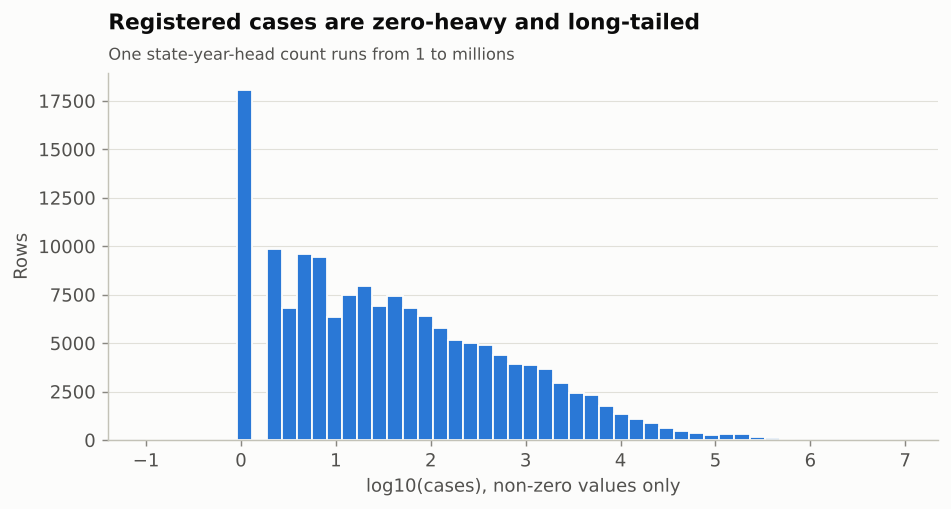

In [6]:
cases = state_year[state_year.metric == "cases_registered"]
print(f"{(cases.value == 0).mean():.1%} of cases_registered values are exactly zero")
print(cases.value.describe(percentiles=[0.5, 0.9, 0.99, 0.999]).round(1).to_string())
viz.show(
    viz.plot_hist(
        np.log10(cases.value[cases.value > 0]),
        "Registered cases are zero-heavy and long-tailed",
        "log10(cases), non-zero values only",
        "One state-year-head count runs from 1 to millions",
        bins=50,
    )
)

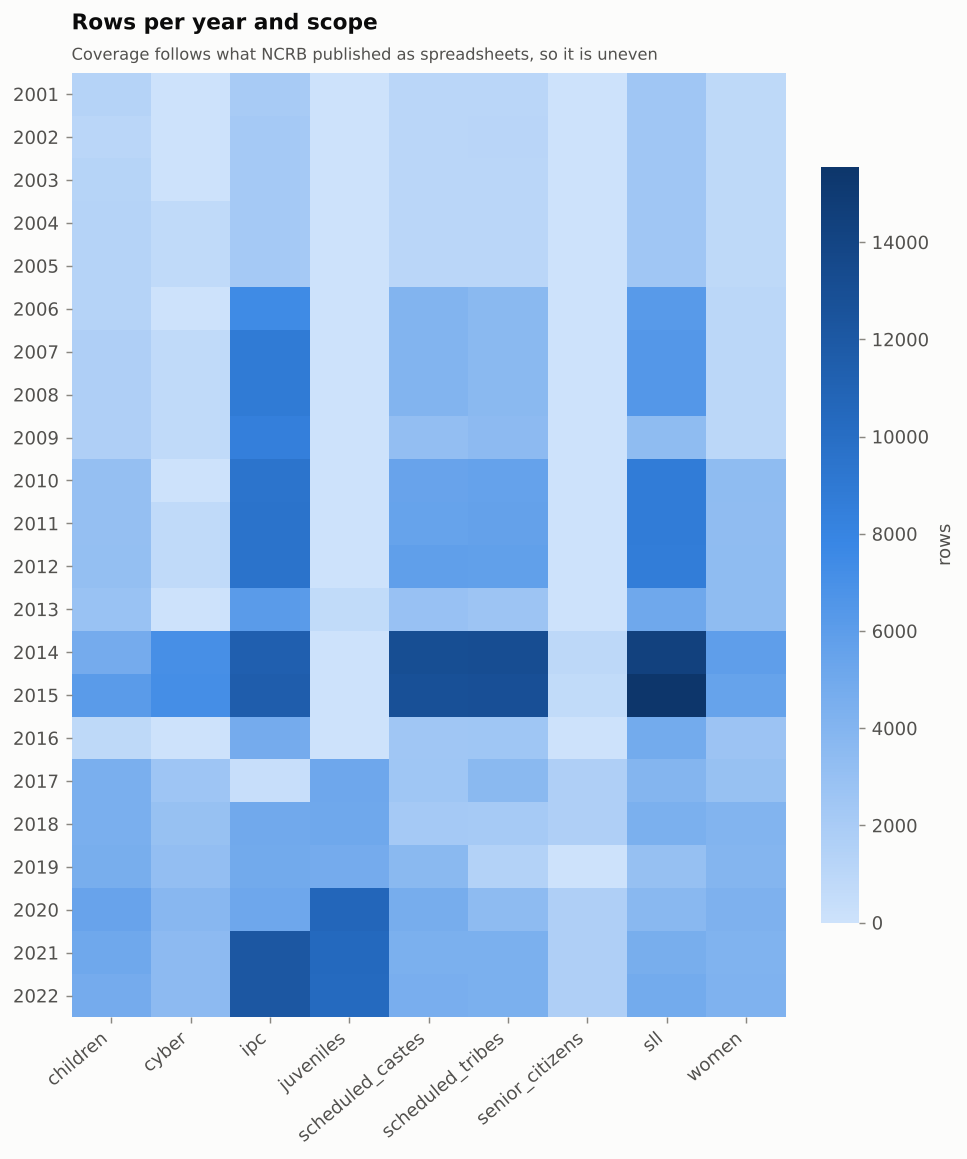

In [7]:
coverage = state_year.pivot_table(index="year", columns="scope", values="value", aggfunc="size", fill_value=0)
viz.show(
    viz.plot_heatmap(
        coverage,
        "Rows per year and scope",
        "Coverage follows what NCRB published as spreadsheets, so it is uneven",
        cbar_label="rows",
    )
)

Coverage is **uneven**: some scopes are missing in many years, 2016 is thin, and the mix of tables changes
from edition to edition. Any model has to cope with series that start, stop and change definition.

## 3. Scopes overlap, so never add across them

The data dictionary warns that one crime can appear in several scope tables. Rape (Sec. 376 IPC) in
Maharashtra, 2021, cases registered, by scope:

In [8]:
mh = state_year[(state_year.state_code == "MH") & (state_year.year == 2021) & (state_year.metric == "cases_registered")]
keys = head_key(mh.crime_head)
rape = mh[keys.str.contains("rape sec 376 ipc") & ~keys.str.contains("attempt|murder|pocso")]
by_scope = rape.groupby("scope").value.max().sort_values(ascending=False)
print(by_scope.to_string())
print()
print(f"adding the scopes gives {by_scope.sum():,.0f}, which is {by_scope.sum() / by_scope['ipc']:.1f}x the "
      f"{by_scope['ipc']:,.0f} the IPC table reports")

scope
ipc                2,496.000
women              2,496.000
scheduled_castes     395.000
juveniles            162.000
scheduled_tribes     145.000
children              28.000
senior_citizens        9.000

adding the scopes gives 5,731, which is 2.3x the 2,496 the IPC table reports


So every `(scope, head)` is its own series in this project and nothing is summed across scopes.

## 4. Does the table check out? State sums against the national table

`crime_india_year.csv` is NCRB's own all-India figure. Summing the state rows should reproduce it.

In [9]:
panel = build_panel(state_year, cfg.task)
state_totals = panel.groupby(["scope", "head_key", "year"], as_index=False).agg(
    state_sum=("cases", "sum"), n_states=("state_code", "nunique")
)
national = india_year[india_year.metric == "cases_registered"].assign(head_key=lambda d: head_key(d.crime_head))
national = national.sort_values(["value", "checked"]).groupby(["scope", "head_key", "year"], as_index=False).tail(1)
joined = state_totals.merge(national[["scope", "head_key", "year", "value"]], on=["scope", "head_key", "year"])
joined = joined[joined.value > 0].assign(ratio=lambda d: d.state_sum / d.value)
joined["states reporting"] = np.where(joined.n_states >= 30, "30 or more", "fewer than 30")

summary = joined.groupby("states reporting").ratio.agg(
    series_years="size", median="median", share_within_1pct=lambda r: ((r - 1).abs() <= 0.01).mean()
)
print(f"{len(joined):,} series-years matched between the two tables")
summary

5,980 series-years matched between the two tables


,series_years,median,share_within_1pct
states reporting,,,
30 or more,5950,1.000,0.969
fewer than 30,30,0.163,0.033


When 30 or more states report a head, the state rows add up to the national figure essentially exactly.
When fewer report it, the state sum is only a fraction of the national number. That is not an error, it is
incomplete reporting, and it is why `n_states` and a head's national `share` are kept as features: they tell
the model how complete a row's context is.

## 5. The news sample is a different kind of data

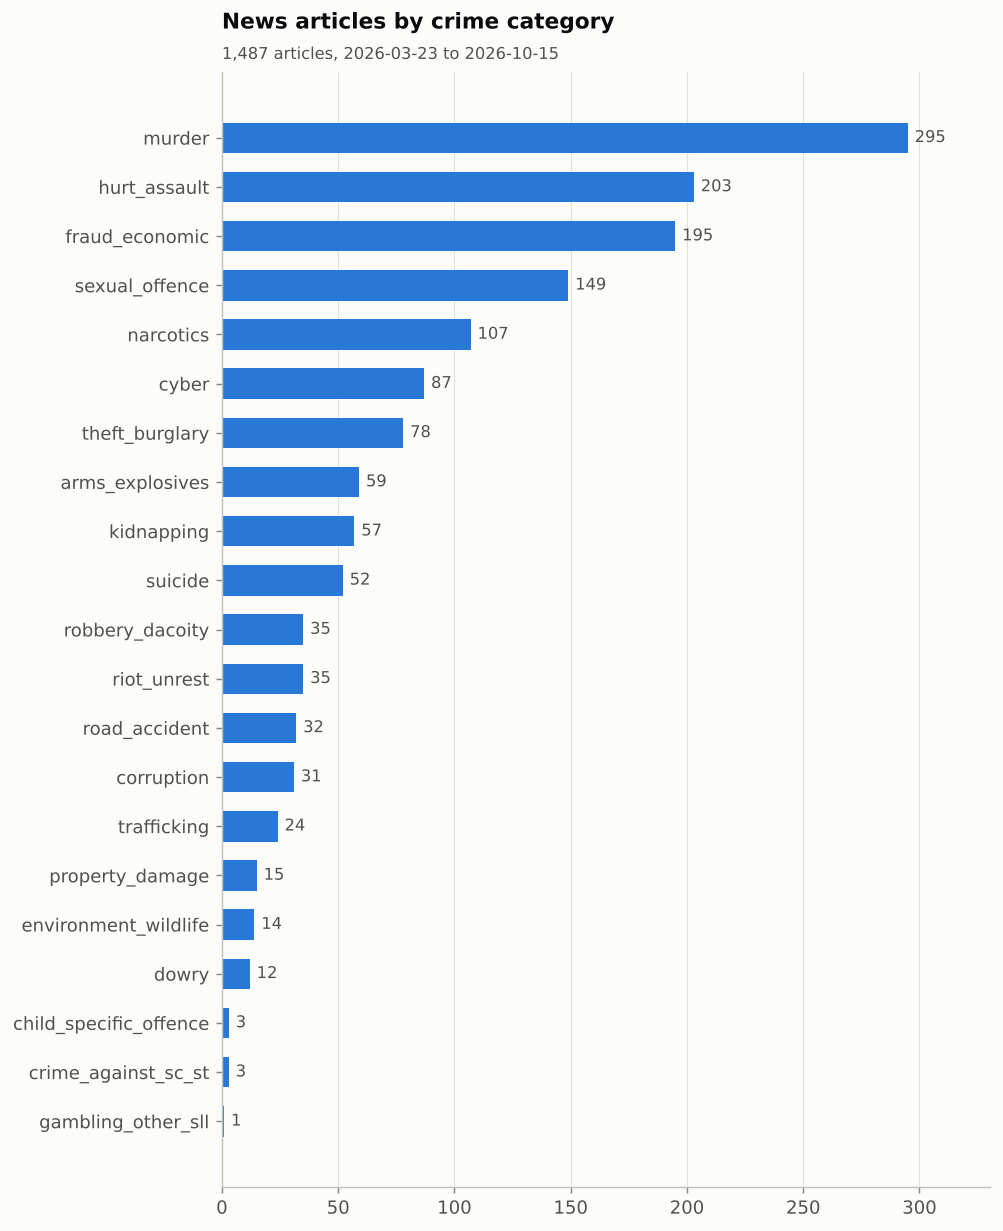

labeller
rules    1487


In [10]:
counts = news.category.value_counts()
viz.show(viz.plot_counts(counts, "News articles by crime category",
                         f"{len(news):,} articles, {news.published.min()} to {news.published.max()}"))
print(news.labeller.value_counts().to_string())

Every article was labelled by a **keyword rule** (`labeller == rules`), not by a person or a model. A
classifier trained on those labels would mostly relearn the keyword list. And titles are withheld on purpose
for the most sensitive categories:

In [11]:
missing = (
    news.assign(title_missing=news.title.isna(), summary_missing=news.summary.isna())
    .groupby("category")[["title_missing", "summary_missing"]].mean()
    .sort_values("title_missing", ascending=False)
)
missing.head(5).style.format("{:.0%}")

,title_missing,summary_missing
category,,
child_specific_offence,100%,100%
sexual_offence,100%,100%
trafficking,21%,62%
kidnapping,5%,39%
road_accident,3%,53%


For `sexual_offence` and `child_specific_offence` the title is missing in **100%** of rows. A model could
"predict" those two classes just from the missing text, which is leakage, not understanding.

## 6. NCRB's registered crime against the news

What does the news cover compared with what is registered? NCRB leaf heads (IPC, 2022) are grouped by
category and compared with the share of news articles. This is approximate: some NCRB sub-head lists still
overlap, so the leaf total is larger than NCRB's own total, which the next cell measures.

leaf heads add up to 5,485,590 cases; the table's own IPC total is 3,561,379 (1.54x). Shares below are therefore indicative.


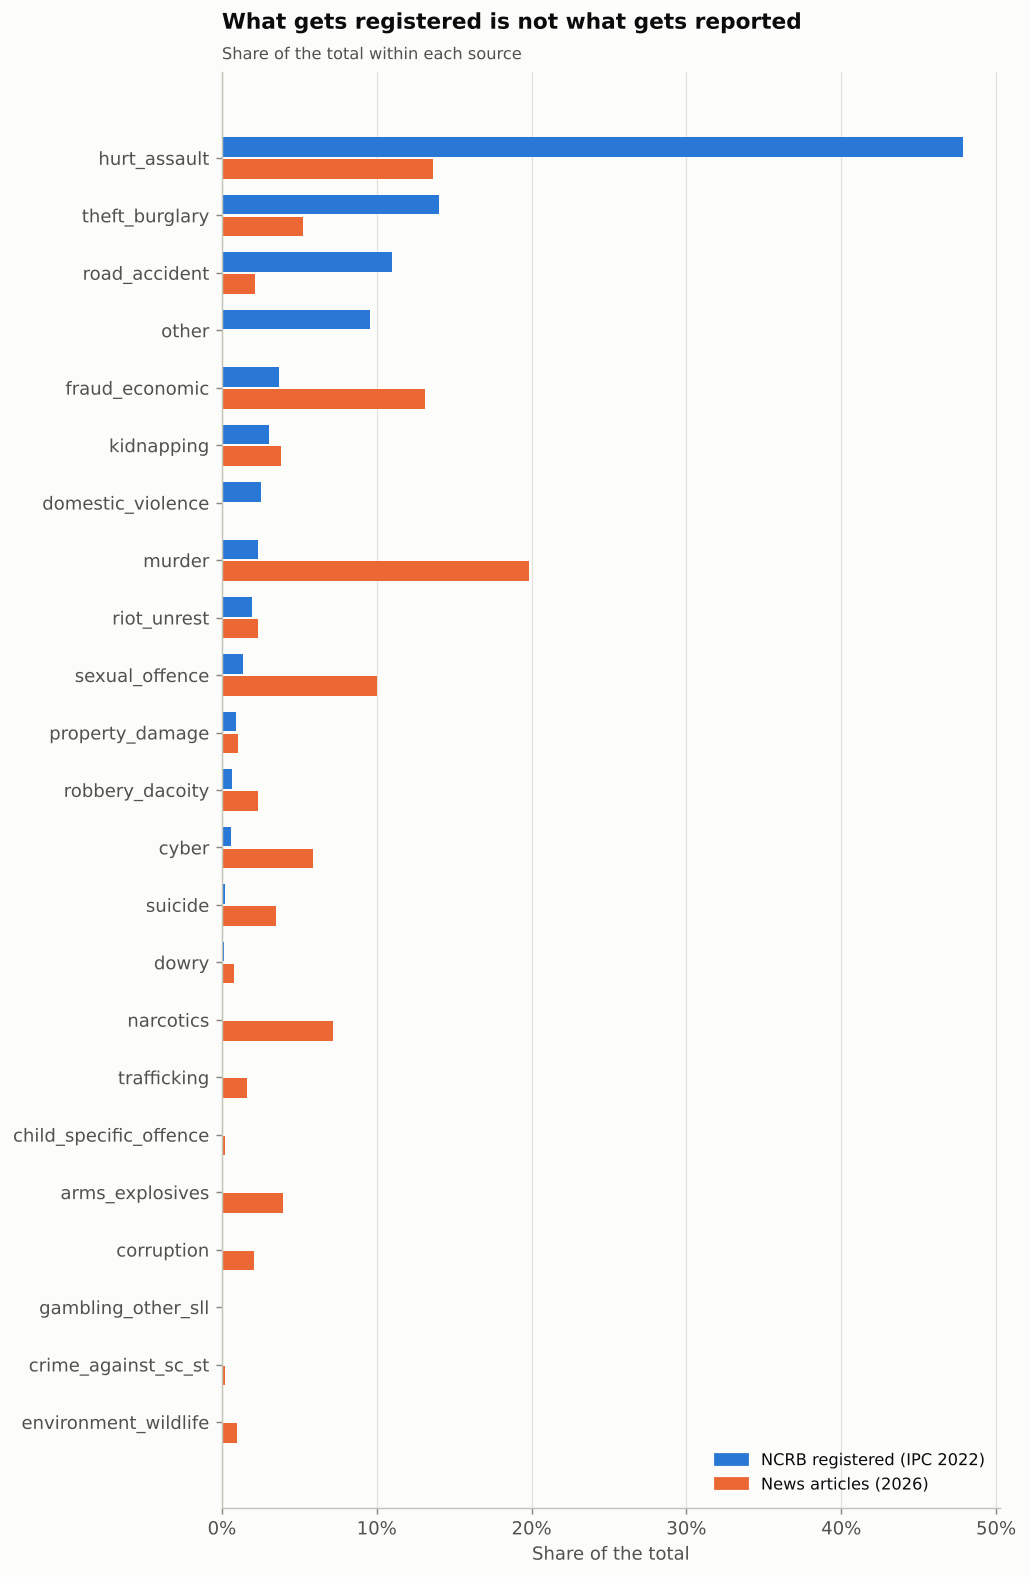

rank correlation between the two category mixes: 0.38


In [12]:
ipc22 = panel[(panel.scope == "ipc") & (panel.year == 2022)].copy()
parents = {h.rsplit(" | ", 1)[0] for h in ipc22.head_key.unique() if " | " in h}
leaf = ipc22[~ipc22.head_key.isin(parents) & ~ipc22.head_key.str.contains("total") & (ipc22.crime_category != "all_crimes")]
reported_total = ipc22.loc[ipc22.head_key == "total cognizable ipc crimes", "cases"].sum()
print(f"leaf heads add up to {leaf.cases.sum():,.0f} cases; the table's own IPC total is {reported_total:,.0f} "
      f"({leaf.cases.sum() / reported_total:.2f}x). Shares below are therefore indicative.")
ncrb_share = leaf.groupby("crime_category").cases.sum()
ncrb_share = ncrb_share / ncrb_share.sum()
news_share = news.category.value_counts(normalize=True)
both = pd.concat([ncrb_share.rename("NCRB registered (IPC 2022)"), news_share.rename("News articles (2026)")], axis=1).fillna(0)
viz.show(viz.plot_share_compare(
    both.iloc[:, 0], both.iloc[:, 1], "NCRB registered (IPC 2022)", "News articles (2026)",
    "What gets registered is not what gets reported", "Share of the total within each source"))
print(f"rank correlation between the two category mixes: {both.corr(method='spearman').iloc[0, 1]:.2f}")

The two sources disagree sharply. Registered crime is dominated by hurt, theft and road accidents; the news
over-represents murder, fraud, sexual offences and drugs. So the news sample cannot stand in for crime
statistics, and the two datasets answer different questions.

## 7. What can honestly be classified?

| Candidate target | Verdict | Why |
|---|---|---|
| Crime category of a crime head | rejected | assigned by a keyword rule on the head text, so a model only relearns the rule |
| Crime category of a news headline | rejected | keyword-rule labels, titles withheld for two classes, only about 1.5k rows |
| Incident-level outcome (arrest, victim, ...) | impossible | the zip holds no incident records |
| **Year-ahead trend of registered cases** | **chosen** | label comes from future counts, not from a rule; multi-class; time-ordered |

The chosen task: for a state/UT and crime head in year *t*, will `cases_registered` in *t+1* go **down**,
stay **stable** or go **up** (a ±10% band)? Notebook 02 turns the raw table into labelled rows.